# 03 — Input di mobilità per il GP

Obiettivo: costruire gli input che il GP userà per β(t).

note:
- **indici**: i due meno correlati fra le categorie legate ai contatti (retail & recreation, grocery & pharmacy, transit stations, workplaces). Esclusi a priori `residential`, che è lo specchio degli altri --se non si è in giro si è a casa--, e `parks`, che segue stagione e meteo e ha 5 giorni mancanti; idealmente, togliamo indicatori ridondanti 
- **media mobile a 7 giorni solo all'indietro**, come per γ(t): nessun dato futuro;
- **normalizzazione**: variazione % / 100 (−40% → −0.4), confrontabile fra finestre;
- **ritardi** 0, 3, 7, 10, 14 giorni: il GP sceglie quali usare. Massimo 14 perché la mobilità parte il 15/02/2020 e la finestra 2020 inizia il 1/3.

Sezioni:
1. Correlazione fra gli indici
2. Costruzione degli input
3. Conclusioni

In [1]:
import itertools
import pandas as pd
import matplotlib.pyplot as plt

from seird_gp.data import PROCESSED_DIR, load_mobility
from seird_gp.inputs import GP_INDICES, LAGS, build_gp_inputs, check_coverage, smooth_past

# serie originale (dal 15/02/2020), non trento_merged.csv (dal 24/02/2020)
mobility = load_mobility()
WINDOWS = {"2020 (1/3–1/4)": ("2020-03-01", "2020-04-01"),
           "2021 (1/3–1/6)": ("2021-03-01", "2021-06-01"),
           "2022 (1/1–1/3)": ("2022-01-01", "2022-03-01")}
print(f"Mobilità: {len(mobility)} giorni, dal {mobility.index.min().date()} al {mobility.index.max().date()}")
mobility.isna().sum()

Mobilità: 974 giorni, dal 2020-02-15 al 2022-10-15


retail_and_recreation    0
grocery_and_pharmacy     0
parks                    5
transit_stations         0
workplaces               0
residential              0
dtype: int64

## 1. Correlazione fra gli indici

Correlazione in valore assoluto (`residential` mostra perché: è correlato negativamente con gli altri, ma è ridondante), su serie lisciate. Sui dati grezzi il ciclo settimanale altera la correlazione. Calcolata sull'intero periodo e dentro ogni finestra, perché è lì che il GP usa gli indici.

In [2]:
SHORT = {"retail_and_recreation": "retail", "grocery_and_pharmacy": "grocery",
         "transit_stations": "transit", "workplaces": "work", "residential": "resid", "parks": "parks"}
CANDIDATES = ["retail", "grocery", "transit", "work"]
smoothed = smooth_past(mobility[list(SHORT)]).rename(columns=SHORT)

print("Tutto il periodo, |r|:")
display(smoothed.corr().abs().round(2))

rows = []
for a, b in itertools.combinations(CANDIDATES, 2):
    row = {"coppia": f"{a} – {b}", "tutto": abs(smoothed[[a, b]].corr().iloc[0, 1])}
    for name, (start, end) in WINDOWS.items():
        row[name] = abs(smoothed.loc[start:end, [a, b]].corr().iloc[0, 1])
    rows.append(row)
pairs = pd.DataFrame(rows).set_index("coppia").sort_values("tutto")
pairs.round(2)

Tutto il periodo, |r|:


,retail,grocery,transit,work,resid,parks
retail,1.00,0.92,0.97,0.61,0.84,0.90
grocery,0.92,1.00,0.89,0.60,0.77,0.84
transit,0.97,0.89,1.00,0.63,0.87,0.88
work,0.61,0.60,0.63,1.00,0.85,0.27
resid,0.84,0.77,0.87,0.85,1.00,0.64
parks,0.90,0.84,0.88,0.27,0.64,1.00


,tutto,2020 (1/3–1/4),2021 (1/3–1/6),2022 (1/1–1/3)
coppia,,,,
grocery – work,0.60,0.99,0.93,0.85
retail – work,0.61,0.99,0.89,0.37
transit – work,0.63,0.99,0.90,0.47
grocery – transit,0.89,0.99,0.93,0.77
retail – grocery,0.92,0.98,0.92,0.68
retail – transit,0.97,1.00,0.99,0.95


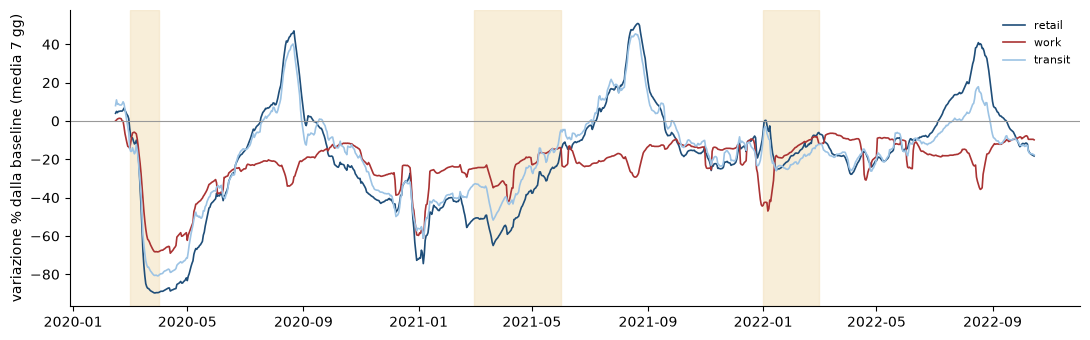

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.5))
for col, color in [("retail", "#1f4e79"), ("work", "#a33"), ("transit", "#9cc3e4")]:
    ax.plot(smoothed[col], color=color, lw=1.2, label=col)
for name, (start, end) in WINDOWS.items():
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="#f4e3c1", alpha=0.6)
ax.axhline(0, color="#999", lw=0.8)
ax.set_ylabel("variazione % dalla baseline (media 7 gg)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

**Lettura.**
- **retail e transit sono lo stesso indice** (|r| 0.95–1.00 in tutte le finestre): ne basta uno. Teniamo retail & recreation: comprende bar, ristoranti e svago, cioè contatti al chiuso, e varia di più nelle finestre.
- **workplaces è l'unico che si stacca**, per la stagionalità: in estate retail sale (turismo) mentre il lavoro scende (ferie). Retail – work è la coppia meno correlata sull'intero periodo (0.60).
- **Dentro le finestre la correlazione cambia molto**: 0.99 nel 2020, 0.89 nel 2021, 0.37 nel 2022. Nel 2020 il lockdown muove tutti gli indici insieme: il GP non potrà distinguere quale conta. Per D6 la distinzione si legge nel 2021 e soprattutto nel 2022.
- **Limite**: in Trentino retail include i turisti, che non sono nella popolazione N del modello (rilevante d'estate e nella stagione sciistica, quindi nel 2022).

**Scelta: retail & recreation + workplaces.**

## 2. Costruzione degli input

`build_gp_inputs` (in `src/seird_gp/inputs.py`): per ogni indice media mobile all'indietro, divisione per 100, poi una colonna per ritardo (`retail_lag0`, …, `work_lag14`). Ai primi giorni della serie (dal 15/02/2020) la media usa meno di 7 giorni: sono giorni pre-pandemia, vicini alla baseline.

`check_coverage` verifica che in ogni finestra nessun input manchi.

In [4]:
inputs = build_gp_inputs(mobility)
coverage = check_coverage(inputs, WINDOWS)   # errore se manca qualcosa
print("Giorni mancanti per finestra (tutti zero):", int(coverage.to_numpy().sum()))
inputs.to_csv(PROCESSED_DIR / "gp_inputs.csv")
inputs.loc["2020-03-01":"2020-03-05"].round(3)

Giorni mancanti per finestra (tutti zero): 0


,retail_lag0,retail_lag3,retail_lag7,retail_lag10,retail_lag14,work_lag0,work_lag3,work_lag7,work_lag10,work_lag14
data,,,,,,,,,,
2020-03-01,-0.039,0.034,0.057,0.052,0.050,-0.143,-0.113,-0.001,0.013,0.005
2020-03-02,-0.077,0.027,0.067,0.051,0.043,-0.116,-0.133,-0.031,0.011,0.010
2020-03-03,-0.090,0.011,0.056,0.051,0.050,-0.084,-0.134,-0.066,0.000,0.012
2020-03-04,-0.089,-0.039,0.043,0.057,0.050,-0.063,-0.143,-0.090,-0.001,0.014
2020-03-05,-0.106,-0.077,0.034,0.067,0.052,-0.060,-0.116,-0.113,-0.031,0.013


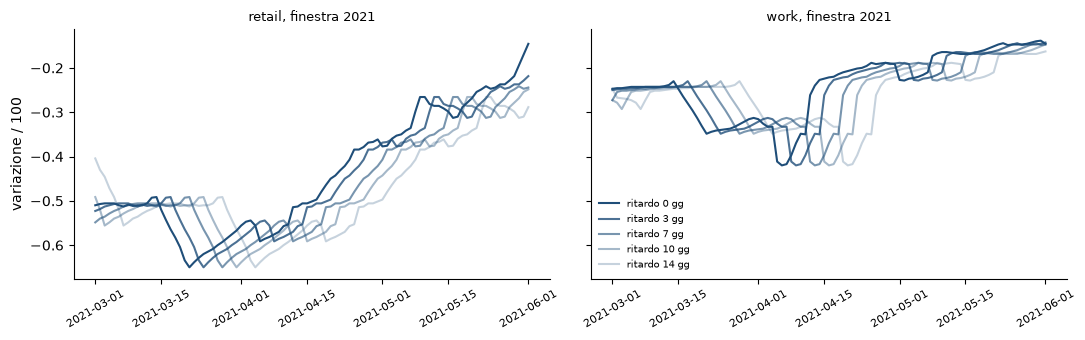

In [5]:
start, end = WINDOWS["2021 (1/3–1/6)"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for axx, name in zip(ax, GP_INDICES.values()):
    for k, alpha in zip(LAGS, [1, 0.8, 0.6, 0.4, 0.25]):
        axx.plot(inputs.loc[start:end, f"{name}_lag{k}"], color="#1f4e79", alpha=alpha, label=f"ritardo {k} gg")
    axx.set_title(f"{name}, finestra 2021", fontsize=9)
    axx.spines[["top", "right"]].set_visible(False)
    axx.tick_params(axis="x", labelrotation=30, labelsize=8)
ax[0].set_ylabel("variazione / 100")
ax[1].legend(frameon=False, fontsize=7)
fig.tight_layout()

## 3. Conclusioni

- Input del GP: 10 colonne, retail e work con ritardi 0, 3, 7, 10, 14 giorni, in `data/processed/gp_inputs.csv`.
- Nel 2020 i due indici sono quasi identici: le formule che usano l'uno o l'altro saranno equivalenti.
- Le versioni ritardate dello stesso indice sono molto correlate: seed diversi sceglieranno ritardi diversi a parità di errore. La distribuzione dei ritardi scelti è un risultato da riportare (D4).
- Il ritardo nella mobilità rappresenta il tempo fra cambio di comportamento e cambio nei contagi: l'incubazione è già nel compartimento E. Ci aspettiamo che contino soprattutto i ritardi bassi.